In [2]:
from xgboost import XGBClassifier

/home/sakdag/miniconda3/envs/fake-news-classification/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


In [3]:
import pandas as pd
import sys
import os

if "Desktop" in os.getcwd():
    base_path = "/Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification"
else:
    base_path = "/home/sakdag/weakly-supervised-fake-news-classification"

print(base_path)
sys.path.append(base_path)
    
from src.utils.path_utils import get_project_root
from src.preprocessing.consts import (
    Datasets,
    DATA_FOLDER_PREFIX,
    Dataset,
    NELA_SOURCE_LABELS,
)
from src.preprocessing.read_raw_data import read_raw_data
from src.preprocessing.read_raw_data import read_csv, save_to_csv
from src.weak_labeling.consts.globals import NLP

from src.weak_labeling.consts.spacy_consts import (
    ADJECTIVE,
    NOUN,
    PRONOUN,
    PROPER_NOUN,
    NUMBER,
    CARDINAL_NUMBER,
    VERB,
    VERB_PRESENT_PARTICIPLE,
    VERB_PAST_PARTICIPLE,
    VERB_THIRD_PERSON,
    DETERMINER,
    ADPOSITION,
    ADVERB,
    COMPARATIVE_ADVERB,
    SUPERLATIVE_ADVERB,
    PERSONAL_PRONOUN,
    POSSESSIVE_PRONOUN,
    INTERJECTION,
    SYMBOL,
    WH_DETERMINER,
    MODAL,
    EXISTENTIAL,
    PUNCTUATION,
    PERIOD,
    QUESTION_MARK,
    COMMA,
    EXCLAMATION_POINT,
    COLON,
    SEMICOLON,
    PARENTHESES_OPEN,
    PARENTHESES_CLOSE,
    QUOTATION_MARK,
    SPACE,
)

# covid_df: pd.DataFrame = read_raw_data(Datasets.NELA_COVID_2021_DATASET)
# elections_df: pd.DataFrame = read_raw_data(Datasets.NELA_ELECTIONS_DATASET_SAMPLED)

/home/sakdag/weakly-supervised-fake-news-classification


In [15]:
path = Datasets.NELA_ELECTIONS_SUBSET_2020.injected_path
injected_df: pd.DataFrame = read_csv(path)

Reading dataset from path: /home/sakdag/weakly-supervised-fake-news-classification/data/feature_injected/nela/nela-elections-subset-2020.csv
Read dataset, dataframe size: 2000


In [18]:
injected_df.head()

,id,title,content,label,content_word_count,content_unique_words_count,content_words_per_sentence,content_stopwords_ratio,content_unique_words_ratio,content_average_sentence_length,...,title_comparative_adverb_ratio,title_superlative_adverb_ratio,title_existential_ratio,title_pronoun_ratio,title_personal_pronoun_ratio,title_possessive_pronoun_ratio,title_punctuation_ratio,content_gunning_fog_index,content_automated_readability_index,content_flesch_kincaid_index
0,dailybeast--2020-08-19--Why Mueller Dropped th...,Why Mueller Dropped the Ball. Was He Corrupt o...,No one really expected the Senate Intelligence...,0,369.0,220.0,16.043478,0.487805,0.596206,18.913043,...,0.0,0.0,0.0,0.100000,0.0,0.0,0.200000,9.615072,7.885774,8.164052
1,eveningstandard--2020-08-28--Donald Trump bran...,Donald Trump brands Joe Biden &apos;destroyer ...,Donald Trump described Joe Biden as the `` des...,0,490.0,274.0,22.272727,0.442857,0.559184,26.954545,...,0.0,0.0,0.0,0.066667,0.0,0.0,0.066667,14.005575,12.225993,11.780337
2,talkingpointsmemo--2020-05-09--Trump Livid Aft...,Trump Livid After California Allows Statewide ...,California Gov .\nGavin Newsom ( D ) issued an...,0,254.0,155.0,19.538462,0.472441,0.610236,22.538462,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.142857,12.685801,10.510374,10.694713
3,thetorontostar--2020-02-04--In embarrassing tw...,"In embarrassing twist, Democrats have no Iowa ...","DES MOINES , Iowa - Democratic party officials...",0,1208.0,541.0,22.792453,0.440397,0.447848,26.301887,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.111111,15.080763,13.794061,12.693341
4,talkingpointsmemo--2020-08-24--House Struggles...,House Struggles To Get Details From DeJoy Abou...,The House s turn to grill embattled Postmaster...,0,803.0,373.0,26.766667,0.483188,0.464508,30.133333,...,0.0,0.0,0.0,0.000000,0.0,0.0,0.000000,15.961736,14.649899,13.552821


In [17]:
injected_df = injected_df.drop(
    [
        'model_xgboost_title_label',
        'model_xgboost_content_label',
        'model_adaboost_title_label',
        'model_adaboost_content_label',
        'model_logistic_regression_title_label',
        'model_logistic_regression_content_label',
        'model_random_forest_title_label',
        'model_random_forest_content_label',
        'model_naive_bayes_title_label',
        'model_naive_bayes_content_label',
    ],
    axis=1
)

KeyError: "['model_xgboost_title_label', 'model_xgboost_content_label', 'model_adaboost_title_label', 'model_adaboost_content_label', 'model_logistic_regression_title_label', 'model_logistic_regression_content_label', 'model_random_forest_title_label', 'model_random_forest_content_label', 'model_naive_bayes_title_label', 'model_naive_bayes_content_label'] not found in axis"

In [ ]:
injected_df.head()

In [8]:
save_to_csv(injected_df, path)

Saving dataframe to: /home/sakdag/weakly-supervised-fake-news-classification/data/feature_injected/nela/nela-elections-2020.csv


In [ ]:
for idx, row in covid_df.sample(n=1000).iterrows():
    print(row.content[:1000])
    print("\n\n\n")
    print("------------------------------")

In [ ]:
for idx, row in covid_df.sample(n=1000).iterrows():
    print(row.title[:1000])
    print("\n\n\n")
    print("------------------------------")

In [ ]:
sampled_df = covid_df.sample(n=1000)

In [ ]:
for idx, row in sampled_df.iterrows():
    print(row.content[:1000])
    print("\n\n\n")
    print("------------------------------")

In [ ]:
for i, row in sampled_df.iterrows():
    val = row["content"].encode("ascii", errors="ignore").decode()
    val =  val.replace(" @ @ @ @ @ @ @", "")
    val =  val.replace(" @ @ @ @ @", "")
    sampled_df.at[i,'content'] = val

In [ ]:
for idx, row in sampled_df.iterrows():
    print(row.content[:1000])
    print("\n\n\n")
    print("------------------------------")

In [2]:

sampled_covid_df: pd.DataFrame = read_raw_data(Datasets.NELA_COVID_2021_DATASET_SAMPLED)

Reading dataset from path: /home/sakdag/weakly-supervised-fake-news-classification/data/raw/nela/nela-covid-2021-sampled.csv
Dataframe size: 666


In [ ]:
for idx, row in sampled_covid_df.iterrows():
    if "@ @ @ @ @" in row.content:
        print(row.content)
        print(row.title)
        print(row.label)
        print("\n\n\n")
        print("------------------------------")

In [ ]:
sampled_covid_df: pd.DataFrame = read_csv(Datasets.NELA_COVID_2021.injected_path)

In [ ]:
print(sampled_elections_df.sample(n=10).head())

In [ ]:
print(sampled_elections_df.value_counts())

In [17]:
sampled_elections_df.label.value_counts()

0    5095
1    4905
Name: model_xgboost_label, dtype: int64

In [ ]:
def is_string_series(s : pd.Series):
    if isinstance(s.dtype, pd.StringDtype):
        # The series was explicitly created as a string series (Pandas>=1.0.0)
        return True
    elif s.dtype == 'object':
        # Object series, check each value
        return all((v is None) or isinstance(v, str) for v in s)
    else:
        return False

In [ ]:
print(is_string_series(covid_df.content))

In [ ]:
print(len(covid_df))
covid_df.dropna(inplace=True)
print(len(covid_df))

In [ ]:
for idx, row in covid_df.iterrows():
    if not isinstance(row.title, str):
        print(row.title)
        break

In [ ]:
print(covid_df.dtypes)
print(len(covid_df))

In [ ]:
from src.utils.preprocessing_utils import cleanup_df

print(len(covid_df))
covid_cleaned_df = cleanup_df(covid_df)
print(len(covid_cleaned_df))

In [ ]:
covid_cleaned_df['content_length']  = covid_cleaned_df['content'].str.len()

In [ ]:
covid_cleaned_df["content"].apply(len).mean()

In [ ]:
covid_cleaned_df.head()

In [ ]:
index = covid_cleaned_df.content_length.argmax()
covid_cleaned_df.iloc[index]

In [ ]:
covid_df_shorter = covid_cleaned_df[covid_cleaned_df['content'].apply(len) < 5000] 

In [ ]:
len(covid_df_shorter)

In [ ]:
covid_df_shorter.hist(column='content_length', bins=200);

In [ ]:
import en_core_web_sm
nlp = en_core_web_sm.load()

In [18]:
import spacy
nlp = spacy.load("en_core_web_sm")

for idx, row in sampled_elections_df.iterrows():
#     print(row.content)
    doc = nlp(row.content)
#     for token in doc:
#         print(token.pos_)
#         print(token)
#         print(type(token))
#     words_lower = [word.text.lower() for word in doc]
#     unique_words = set(words_lower)
#     print(words_lower)
#     print(unique_words)
#     print(len(words_lower))
#     print(len(unique_words))
    sentence_lengths = []
    for sentence in doc.sents:
        sentence_lengths.append(len(sentence))
        print(sentence)
    print(sentence_lengths)
    break

TULSA ( The Borowitz Report )
Stung by the paltry turnout at his Saturday-night rally in Tulsa , Oklahoma , campaign has announced plans to hold his next rally in the bunker beneath the White rally , Brad Parscale , the chairman of Trump s relection campaign , denied reflected a tepid level of enthusiasm to see the candidate speak .

 The bunker Parscale said .

 That is a much larger seating capacity than Joe Biden choice of such an intimate venue , however , Trump campaign sources are privately worried filling the bunker .


According to one source , Jared Kushner spent all of Sunday people to attend the bunker rally .

 All of Jared s friends said so that s five seats right there , the source said .
[6, 57, 6, 30, 1, 18, 19]


In [10]:
Datasets.NELA_COVID_2021.injected_path

'feature_injected/nela/nela-covid-2021-sampled.csv'

In [2]:
injected_df: pd.DataFrame = read_csv(Datasets.NELA_COVID_2021.injected_path)
# injected_df: pd.DataFrame = read_csv('temp/nela-covid-2021-sampled.csv')

Reading dataset from path: /Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification/data/feature_injected/nela/nela-covid-2021-sampled.csv
Read dataset, dataframe size: 10000


In [4]:
injected_df.label.value_counts()

0    5000
1    5000
Name: label, dtype: int64

<AxesSubplot: ylabel='Density'>

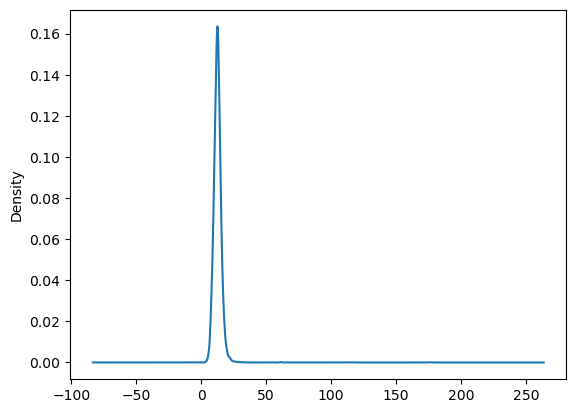

In [12]:
injected_df['content_flesch_kincaid_index'].plot(kind='kde')

In [13]:
print(injected_df['content_flesch_kincaid_index'].min())
print(injected_df['content_flesch_kincaid_index'].max())

3.3935872675250387
176.8958198071042


In [3]:
text = sampled_df.sample(n=1).content.iloc[0]

In [4]:
from readability import Readability

readability = Readability(text)

In [14]:
!conda remove py-readability-metrics

# packages in environment at /home/sakdag/miniconda3/envs/fake-news-classification:
#
# Name                    Version                   Build  Channel
py-readability-metrics    1.4.5              pyhd8ed1ab_0    conda-forge


In [5]:
injected_df: pd.DataFrame = read_csv(Datasets.NELA_ELECTIONS_2020.injected_path)

Reading dataset from path: /Users/sakdag/Desktop/masters/weakly-supervised-fake-news-classification/data/feature_injected/nela/nela-elections-2020-sampled.csv
Read dataset, dataframe size: 50000


In [7]:
for col in injected_df.columns:
    count = (injected_df[col] == 0).sum()
    print(f"{col}: {count}")

id: 0
title: 0
content: 0
label: 25000
content_word_count: 0
content_unique_words_count: 0
content_words_per_sentence: 0
content_stopwords_ratio: 0
content_unique_words_ratio: 0
content_average_sentence_length: 0
content_average_word_length: 0
content_noun_ratio: 0
content_proper_noun_ratio: 2
content_cardinal_number_ratio: 995
content_determiner_ratio: 1
content_adposition_ratio: 0
content_interjection_ratio: 33689
content_symbol_ratio: 31118
content_adjective_ratio: 0
content_wh_determiner_ratio: 4745
content_verb_ratio: 0
content_verb_present_participle_ratio: 101
content_verb_past_participle_ratio: 92
content_verb_third_person_ratio: 1671
content_modal_ratio: 1998
content_adverb_ratio: 23
content_comparative_adverb_ratio: 21213
content_superlative_adverb_ratio: 29455
content_existential_ratio: 22330
content_pronoun_ratio: 10
content_personal_pronoun_ratio: 6053
content_possessive_pronoun_ratio: 1216
content_punctuation_ratio: 0
content_period_ratio: 0
content_question_mark_ration: 

In [4]:
for idx, row in injected_df.iterrows():
    if QUESTION_MARK in row.content:
        print("found")
        print(row.content)
        print("\n--------------------\n")

        content_spacy = NLP(row.content)
        for token in content_spacy:
            # print(token.text)
            if token.text == QUESTION_MARK:
                print(token.pos_)
                print(token.tag_)
                print(token.text)

        break

found
Minister of Employment Carla Qualtrough , pictured at the committee on government operations and estimates in Ottawa in November 2017 .
( Matthew Usherwood/iPolitics ) Today s Morning Brief is brought to you by Chartered Professional Accountants of Canada .
Transitioning to a net-zero emission economy requires sustainable finance .
Our policy brief looks at steps the federal government can take to enable a more sustainable and prosperous future .
You can listen to today s brief here : EI unlikely for vaccine refusers : Employment Minister Carla Qualtrough says people who lose their jobs for not be eligible for employment insurance .
 It s a condition of employment that hasn t been met , she told CBC News .
She said that would not apply to people who have valid reasons for not being vaccinated , such as a medical exemption .
 Blanket travel advisory quietly lifted : Canada quietly removed a blanket advisory against all non-essential international travel , which had been in place s

In [18]:
a_text = "This could work."
s_text = NLP(a_text)
for token in s_text:
    print(f"pos: {token.pos_}, tag: {token.tag_}")

pos: PRON, tag: DT
pos: AUX, tag: MD
pos: VERB, tag: VB
pos: PUNCT, tag: .


In [ ]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer('distilbert-base-nli-mean-tokens')

sentences = [
    'the person wear red T-shirt',
    'this person is walking',
    'the boy wear red T-shirt'
    ]
sentence_embeddings = model.encode(sentences)

for sentence, embedding in zip(sentences, sentence_embeddings):
    print("Sentence:", sentence)
    print("Embedding:", embedding)
    print("")

In [20]:
from sentence_transformers import util
print(util.pytorch_cos_sim(sentence_embeddings[0], sentence_embeddings[1]))
print(util.pytorch_cos_sim(sentence_embeddings[0], sentence_embeddings[2]))
print(util.pytorch_cos_sim(sentence_embeddings[1], sentence_embeddings[2]))

tensor([[0.4644]])
tensor([[0.9070]])
tensor([[0.3276]])


In [32]:
title = "I am some other text!"
title_embedding = model.encode(title)
spacy_s = NLP("Hey there. How are you. Hope you are better")
similarities = []
for sentence in spacy_s.sents:
    print(sentence)
    current_sentence_embedding = model.encode(str(sentence))
    similarities.append(
        float(util.pytorch_cos_sim(title_embedding, current_sentence_embedding))
    )

Hey there.
How are you.
Hope you are better


In [35]:
from statistics import mean

mean(similarities)

0.595645546913147